# 1. Calibration: how each spot threshold was chosen

**Step 3 of the workflow** (see the README). Input: `outputs/<plate>/aggregated/` from step 2. Runs on a laptop.

Every local maximum of the Laplacian-of-Gaussian (LoG) filtered image is a *candidate* spot, stored with its LoG
score down to a low floor. A candidate counts as an mRNA when its score reaches the threshold for its **probe and
channel**, one value for the whole plate, so counts compare across wells and cell lines.

**The rule.** Each threshold comes from a negative control imaged in the same channel with the same detection
kernel: a probe whose target is absent, so every spot it gives is false.

| Control | Wells | Sets the threshold of |
|---|---|---|
| mrcB (bacterial gene) in Atto565 | W1 | every Atto565 mRNA probe |
| mrcB in Atto633 | W6 | every Atto633 mRNA probe |
| NeoR in the parental line (no neo cassette) | W5, W9 | NeoR |
| TetO-MS2 in the parental line (no knock-in) | W15 | TetO (transcription sites) |

The threshold is the lowest score at which the control gives **at most 1 false spot per cell** (mRNA probes) or
**at most 0.1 per nucleus** (transcription-site probes, which count 1-2 real sites per nucleus). The false-spot
rate is taken in each field of view and the **median over fields** is used, so a few fields with non-specific
staining cannot set the plate's threshold. POLR2A / CTCF introns in Atto565 have no control and use the median
of the per-field automated (elbow) thresholds.

Sections: 1 the thresholds in use; 2 clumps of non-specific staining; 3 control against real signal;
4 detection efficiency (odds / evens); 5 do the conclusions hinge on the threshold?; 6 position in the field;
7 single-mRNA references; 8 (optional, needs one raw image) one field from raw image to counted spots.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from smfish import style as S
from smfish.calibrate import threshold_scan
from smfish.figures import label_panels, save
from smfish.layout import load_layout
from smfish.notebook import setup
from smfish.robustness import fig_threshold_robustness, readouts_vs_threshold

PLATE = os.environ.get("SMFISH_PLATE", "250806")
plate = setup(PLATE, "calibration")
cal = plate.agg / "calibration"
cells = pd.read_parquet(plate.agg / "cells.parquet")
layout = load_layout(plate.cfg)
print(f"plate {PLATE}: {plate.rel(plate.agg)}, {int(cells['qc_pass'].sum())} QC cells in {cells['fov_id'].nunique()} fields")

plate 250806: outputs/250806/aggregated, 7194 QC cells in 425 fields


## 1. The thresholds in use, and whether the controls still give them
`in config`: what step 2 applied (`aggregation.thresholds` in `config/<plate>/experiment.yaml`). `proposed`: what
the rule gives on this run's controls. They agree to within 1%: clump detection (section 2) depends on the applied
threshold, so recalibrating after it moves a value by about 0.01.

In [2]:
applied = pd.read_csv(cal / "thresholds_applied.csv")
proposed = pd.read_csv(cal / "proposed_thresholds.csv")
thresholds = (proposed[["probe", "channel", "kernel", "proposed", "source", "fp_per_cell_at_proposed"]]
              .merge(applied[["probe", "channel", "threshold_median"]].rename(columns={"threshold_median": "in config"}),
                     on=["probe", "channel"], how="outer"))
thresholds["agrees"] = np.isclose(thresholds["proposed"], thresholds["in config"], rtol=0.01)
thresholds.to_csv(plate.results / "thresholds.csv", index=False)
display(thresholds.round(3))
if thresholds["agrees"].all():
    print("The thresholds in the config are the ones the controls give (within 1%).")
else:
    print("Paste into aggregation.thresholds in the config, then re-run step 2:\n")
    print((cal / "proposed_thresholds.yaml").read_text())

,probe,channel,kernel,proposed,source,fp_per_cell_at_proposed,in config,agrees
0,CTCF intron,Atto565,intron,1.465,median per-FOV auto (no negative control),NaN,1.46,True
1,GAPDH exon,Atto565,exon,7.702,"negative control mrcB (wells 1), same channel ...",1.000,7.70,True
2,GAPDH exon,Atto633,exon,7.354,"negative control mrcB (wells 6), same channel ...",1.000,7.34,True
3,NeoR,Atto633,exon,7.325,"own negative control (wells 5,9)",1.053,7.33,True
4,POLR2A evens exon,Atto633,exon,7.354,"negative control mrcB (wells 6), same channel ...",1.000,7.34,True
5,POLR2A intron,Atto565,intron,3.071,median per-FOV auto (no negative control),NaN,3.07,True
6,POLR2A odds exon,Atto565,exon,7.702,"negative control mrcB (wells 1), same channel ...",1.000,7.70,True
7,POLR2B evens exon,Atto633,exon,7.354,"negative control mrcB (wells 6), same channel ...",1.000,7.34,True
8,POLR2B odds exon,Atto565,exon,7.702,"negative control mrcB (wells 1), same channel ...",1.000,7.70,True
9,TetO MS2 intron,Atto633,intron,2.300,own negative control (wells 15),0.094,2.30,True


The thresholds in the config are the ones the controls give (within 1%).


## 2. Clumps of non-specific staining
Some fields carry extended bright aggregates (e.g. Atto633 on top of a few cells) that the LoG splits into dozens of
candidates. They are not spot-like, so they count neither as mRNAs nor as false positives in calibration
(`smfish/clumps.py`). They are told apart by their **local background** (~100 counts under a clump candidate,
12-22 under a real spot): a clump is >= 4 linked candidates whose background is > 5x the typical background in
their own well and channel, spanning >= 1.5 µm. Spots above threshold in QC cells, and how many sit in clumps:

In [3]:
clumps = pd.read_csv(cal / "clumps_by_well.csv")
display(clumps[clumps["in_clumps"] > 0].round(3))
print(f"{int(clumps['in_clumps'].sum())} of {int(clumps['spots'].sum())} spots above threshold "
      f"({clumps['in_clumps'].sum() / clumps['spots'].sum():.2%}) sit in clumps, in "
      f"{(clumps['in_clumps'] > 0).sum()} of {len(clumps)} well / probe combinations")

,well,channel,probe,spots,in_clumps,fraction,fields_with_clumps
6,4,Atto565,POLR2A intron,381,20,0.052,2
7,4,Atto633,NeoR,3047,15,0.005,1
9,5,Atto633,NeoR,480,4,0.008,1
10,6,Atto565,GAPDH exon,494663,45,0.000,1
11,6,Atto633,mrcB,641,153,0.239,4
13,7,Atto633,POLR2B evens exon,22535,1,0.000,1
15,8,Atto633,NeoR,15282,6,0.000,1
16,9,Atto565,POLR2A odds exon,49123,6,0.000,1
17,9,Atto633,NeoR,686,40,0.058,2
21,11,Atto633,POLR2A evens exon,37093,170,0.005,2


690 of 984342 spots above threshold (0.07%) sit in clumps, in 17 of 34 well / probe combinations


## 3. Control against real signal
Spots per cell at or above each LoG score, for the control (purple; solid: median over fields, the rule; dashed:
all fields pooled) and for a real target in the same channel and kernel (black). The threshold (orange) is where
the control's median curve crosses the allowed false-positive rate (grey). Real signal stays far above it.

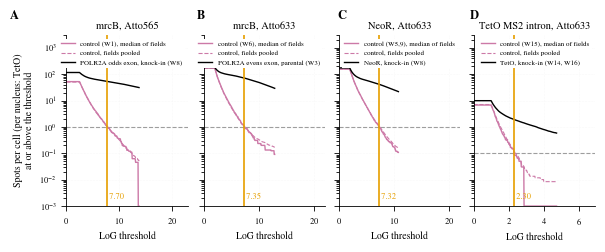

In [4]:
# Real target drawn next to each control: same channel and detection kernel
TARGETS = {("mrcB", "Atto565"): ("POLR2A odds exon", [8], "POLR2A odds exon, knock-in (W8)"),
           ("mrcB", "Atto633"): ("POLR2A evens exon", [3], "POLR2A evens exon, parental (W3)"),
           ("NeoR", "Atto633"): ("NeoR", [8], "NeoR, knock-in (W8)"),
           ("TetO MS2 intron", "Atto633"): ("TetO MS2 intron", [14, 16], "TetO, knock-in (W14, W16)")}

curve = pd.read_csv(cal / "negative_control_curve.csv")
nct = pd.read_csv(cal / "negative_control_thresholds.csv")
nct = nct.assign(order=nct["probe"].map({"mrcB": 0, "NeoR": 1})).sort_values(["order", "channel"])  # TetO last
qc = cells[cells["qc_pass"]]
target_wells = sorted({w for _, ws, _ in TARGETS.values() for w in ws})
cand = pd.read_parquet(plate.agg / "spots.parquet", filters=[("well", "in", target_wells)],
                       columns=["fov_id", "cell_id", "well", "channel", "probe", "log_score", "in_nucleus", "in_clump"])
cand = cand[~cand["in_clump"]].merge(qc[["fov_id", "cell_id"]], on=["fov_id", "cell_id"])


def per_cell_above(scores, grid, n_cells):
    s = np.sort(scores)
    return (s.size - np.searchsorted(s, grid, side="left")) / n_cells


with S.use("publication"):
    fig, axes = plt.subplots(1, len(nct), figsize=(S.TEXT_WIDTH_MM * S.MM, 58 * S.MM), layout="constrained",
                             sharey=True)
    for ax, (_, r) in zip(np.atleast_1d(axes), nct.iterrows()):
        c = curve[(curve["channel"] == r["channel"]) & (curve["probe"] == r["probe"]) & (curve["kernel"] == r["kernel"])]
        per = "nucleus" if r["counted"] == "nucleus" else "cell"
        ax.plot(c["threshold"], c["fp_per_cell_median"].clip(lower=1e-3), color=S.PURPLE,
                label=f"control (W{r['wells']}), median of fields")
        ax.plot(c["threshold"], c["fp_per_cell_pooled"].clip(lower=1e-3), color=S.PURPLE, ls="--", lw=0.8,
                label="control, fields pooled")
        probe, wells, label = TARGETS[(r["probe"], r["channel"])]
        t = cand[(cand["probe"] == probe) & (cand["channel"] == r["channel"]) & cand["well"].isin(wells)]
        if per == "nucleus":
            t = t[t["in_nucleus"]]
        n = int(qc["well"].isin(wells).sum())
        ax.plot(c["threshold"], per_cell_above(t["log_score"].to_numpy(), c["threshold"].to_numpy(), n).clip(1e-3),
                color=S.BLACK, label=label)
        ax.axhline(r["max_fp_per_cell"], **S.REFERENCE_LINE)
        ax.axvline(r["threshold"], color=S.ORANGE, lw=1.2)
        ax.text(r["threshold"], 0.03, f" {r['threshold']:.2f}", color=S.ORANGE, fontsize=6,
                transform=ax.get_xaxis_transform(), ha="left", va="bottom")
        ax.set(yscale="log", ylim=(1e-3, 3e3), xlim=(0, 3 * r["threshold"]), xlabel="LoG threshold",
               title=f"{r['probe']}, {r['channel']}")
        ax.legend(fontsize=5, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("Spots per cell (per nucleus: TetO)\nat or above the threshold")
    label_panels(fig, [(ax, chr(65 + i)) for i, ax in enumerate(np.atleast_1d(axes))])
    save(fig, "calibration_curves", plate.figures)
    plt.show()

## 4. Detection efficiency at these thresholds: odds / evens
In the odds / evens wells two probe sets tile alternating stretches of one mRNA, one per channel, so nearly every
real molecule should show in both. For each channel, the detection efficiency is the share of confidently
detected spots in the *other* channel (top half by score, above their field's automated threshold) that have a
spot within 400 nm at or above the threshold. A well whose evens staining failed (fewer than a quarter as many
evens as odds spots per cell; 250806 W2) cannot measure it and is left out.

probe_set,evens,odds,odds per cell,evens per cell,usable
well,,,,,
2,POLR2A evens exon,POLR2A odds exon,53.7,0.7,False
3,POLR2A evens exon,POLR2A odds exon,102.7,71.3,True
7,POLR2B evens exon,POLR2B odds exon,69.4,60.7,True


,channel,threshold,wells,detection_efficiency
0,Atto565,7.70,"3,7",0.974
1,Atto633,7.34,"3,7",0.933


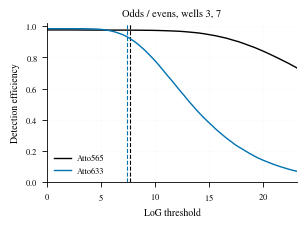

In [5]:
MIN_EVENS_PER_ODDS = 0.25
oe = layout[layout["probe_set"].isin(["odds", "evens"])].pivot_table(index="well", columns="probe_set",
                                                                      values="probe", aggfunc="first").dropna()
oe = oe[oe["odds"].str.replace(" odds exon", "") == oe["evens"].str.replace(" evens exon", "")]
long = pd.read_parquet(plate.agg / "cell_counts_long.parquet")
per_cell = (long[long["well"].isin(oe.index)].merge(qc[["fov_id", "cell_id"]], on=["fov_id", "cell_id"])
            .groupby(["well", "probe"])["n_spots"].sum() / qc[qc["well"].isin(oe.index)].groupby("well").size())
oe["odds per cell"] = [per_cell.get((w, p), 0) for w, p in oe["odds"].items()]
oe["evens per cell"] = [per_cell.get((w, p), 0) for w, p in oe["evens"].items()]
oe["usable"] = oe["evens per cell"] >= MIN_EVENS_PER_ODDS * oe["odds per cell"]
display(oe.round(1))

use = oe.index[oe["usable"]].tolist()
sp = pd.read_parquet(plate.agg / "spots.parquet", filters=[("well", "in", use)],
                     columns=["fov_id", "cell_id", "well", "channel", "probe", "gene", "role", "expected_absent",
                              "log_score", "auto_threshold", "z_um", "y_um", "x_um", "in_clump"])
scan = threshold_scan(sp[~sp["in_clump"]], cells, plate.cfg["tss"]["colocalisation_distance_nm"],
                      plate.cfg["tss"].get("channel_offsets_um"))
thr_of = {ch: float(applied.loc[(applied["channel"] == ch) & applied["probe"].isin(oe[col]), "threshold_median"].iloc[0])
          for ch, col in (("Atto565", "odds"), ("Atto633", "evens"))}
detection = pd.DataFrame([{"channel": ch, "threshold": t, "wells": ",".join(map(str, use)),
                           "detection_efficiency": float(np.interp(t, *scan.loc[scan["channel"] == ch,
                                                                                ["threshold", "detection_rate"]].T.values))}
                          for ch, t in thr_of.items()])
detection.to_csv(plate.results / "detection_efficiency.csv", index=False)
display(detection.round(3))

with S.use("publication"):
    fig, ax = plt.subplots(figsize=(75 * S.MM, 55 * S.MM), layout="constrained")
    for ch, colour in (("Atto565", S.BLACK), ("Atto633", S.BLUE)):
        d = scan[scan["channel"] == ch]
        ax.plot(d["threshold"], d["detection_rate"], color=colour, label=ch)
        ax.axvline(thr_of[ch], color=colour, ls="--", lw=0.8)
    ax.set(xlabel="LoG threshold", ylabel="Detection efficiency", ylim=(0, 1.02), xlim=(0, 3 * max(thr_of.values())),
           title=f"Odds / evens, wells {', '.join(map(str, use))}")
    ax.legend(loc="lower left")
    save(fig, "detection_efficiency", plate.figures)
    plt.show()

## 5. Do the conclusions hinge on the exact threshold?
Every threshold scaled by the same factor (0.6-1.6x) and the spots recounted from the stored candidates.
Counts fall smoothly as the threshold rises; the controls fall much faster than real signal. The comparison
between cell lines and the size-scaling slopes (notebook 2, section 3) change little within +-20% (shaded).

group,"NeoR, parental (W5, W9)","POLR2A, knock-in (W2, W8, W16)","POLR2A, parental (W3, W9)","mrcB, Atto565 (W1)","mrcB, Atto633 (W6)","POLR2A per pL, knock-in / parental"
factor,,,,,,
0.6,10.267,72.230,117.352,7.249,8.935,0.547
0.7,5.415,66.985,108.318,4.175,4.784,0.550
0.8,2.984,63.156,103.048,2.562,2.742,0.545
0.9,1.739,59.781,99.388,1.665,1.633,0.535
1.0,1.064,56.688,96.670,1.044,1.023,0.521
1.1,0.651,53.555,94.238,0.709,0.690,0.505
1.2,0.411,50.546,92.015,0.475,0.486,0.488
1.3,0.279,47.656,89.799,0.328,0.371,0.472
1.4,0.188,44.782,87.527,0.212,0.298,0.455


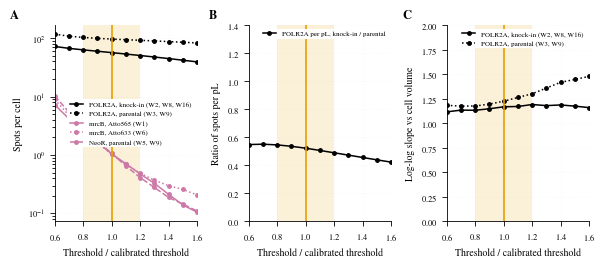

In [6]:
# The main readout (notebook 2): POLR2A odds exon in every well of each cell line, and the negative controls
GROUPS = {"POLR2A, knock-in (W2, W8, W16)": ("POLR2A odds exon", "Atto565", [2, 8, 16]),
          "POLR2A, parental (W3, W9)": ("POLR2A odds exon", "Atto565", [3, 9]),
          "mrcB, Atto565 (W1)": ("mrcB", "Atto565", [1]),
          "mrcB, Atto633 (W6)": ("mrcB", "Atto633", [6]),
          "NeoR, parental (W5, W9)": ("NeoR", "Atto633", [5, 9])}
robust = readouts_vs_threshold(plate.agg, GROUPS)
robust.to_csv(plate.results / "threshold_robustness.csv", index=False)
wide = robust.pivot(index="factor", columns="group", values="spots_per_cell")
wide["POLR2A per pL, knock-in / parental"] = (robust.pivot(index="factor", columns="group", values="spots_per_pL")
                                              .pipe(lambda t: t[list(GROUPS)[0]] / t[list(GROUPS)[1]]))
display(wide.round(3))
with S.use("publication"):
    fig = fig_threshold_robustness(robust, readouts=list(GROUPS)[:2], controls=list(GROUPS)[2:],
                                   ratios={"POLR2A per pL, knock-in / parental": tuple(list(GROUPS)[:2])})
    save(fig, "threshold_robustness", plate.figures)
    plt.show()

## 6. Position in the field
Illumination falls off towards the edges of each field of view: single mRNAs near the edges are markedly dimmer than
in the centre (the measured fall-off is in section 7), and so is the background that false spots come from. One threshold for the whole
field is therefore more permissive in the centre and stricter at the edges: the rule's <= 1 false spot per cell
holds on average over the field, not in every part of it. Readouts below by the position of the cell's centre
(distance from the field centre as a fraction of the half-width: centre < 0.4, middle < 0.7, outer < 1, corner).
Concentrations near the edges are underestimated, but both cell lines are imaged with the same field geometry, so
the comparison between them does not depend on position. A position-dependent threshold was tested and not
adopted: it flattens these profiles but leaves the plate-wide readouts within a few percent.

In [7]:
voxel_xy = plate.cfg["voxel_size_um"]["expected"][1]
xy = pd.read_parquet(plate.agg / "spots.parquet", filters=[("well", "==", 1)], columns=["y_px", "x_px"])
half = (max(xy["y_px"].max(), xy["x_px"].max()) + 1) / 2 * voxel_xy          # field half-width in µm
r = np.hypot(qc["centroid_y_um"] - half, qc["centroid_x_um"] - half) / half
RINGS = ["centre", "middle", "outer", "corner"]
by_ring = qc.assign(ring=pd.cut(r, [0, 0.4, 0.7, 1.0, 1.5], labels=RINGS))[["fov_id", "cell_id", "well", "ring",
                                                                              "cell_volume_um3"]]
POSITION = {"mrcB, Atto565 (W1): false spots per cell": ("mrcB", "Atto565", [1], "cell"),
            "mrcB, Atto633 (W6): false spots per cell": ("mrcB", "Atto633", [6], "cell"),
            "NeoR, parental (W5, W9): false spots per cell": ("NeoR", "Atto633", [5, 9], "cell"),
            "TetO, parental (W15): false sites per nucleus": ("TetO MS2 intron", "Atto633", [15], "nucleus"),
            "POLR2A per pL, knock-in (W2, W8, W16)": ("POLR2A odds exon", "Atto565", [2, 8, 16], "per pL"),
            "POLR2A per pL, parental (W3, W9)": ("POLR2A odds exon", "Atto565", [3, 9], "per pL")}
rows = []
for label, (probe, channel, wells, unit) in POSITION.items():
    d = long[(long["probe"] == probe) & (long["channel"] == channel) & long["well"].isin(wells)]
    if unit == "nucleus":
        d = d[d["compartment"] == "nucleus"]
    n = d.groupby(["fov_id", "cell_id"])["n_spots"].sum()
    c = by_ring[by_ring["well"].isin(wells)].set_index(["fov_id", "cell_id"])
    c["n"] = n.reindex(c.index, fill_value=0)
    if unit == "per pL":
        per = c.groupby("ring", observed=True).apply(lambda t: t["n"].sum() / t["cell_volume_um3"].sum() * 1000,
                                                     include_groups=False)
        total = c["n"].sum() / c["cell_volume_um3"].sum() * 1000
    else:
        per, total = c.groupby("ring", observed=True)["n"].mean(), c["n"].mean()
    rows.append({"readout": label, **per.to_dict(), "whole field": total})
position = pd.DataFrame(rows).set_index("readout")
position.loc["POLR2A per pL, knock-in / parental"] = (position.iloc[-2] / position.iloc[-1])
position.loc["QC cells (all wells)"] = by_ring.groupby("ring", observed=True).size().reindex(RINGS).tolist() + [len(by_ring)]
position.to_csv(plate.results / "position_in_field.csv")
display(position.round(2))

,centre,middle,outer,corner,whole field
readout,,,,,
"mrcB, Atto565 (W1): false spots per cell",2.17,1.22,0.53,0.26,1.04
"mrcB, Atto633 (W6): false spots per cell",2.32,1.01,0.22,0.08,1.02
"NeoR, parental (W5, W9): false spots per cell",2.75,1.03,0.20,0.20,1.06
"TetO, parental (W15): false sites per nucleus",0.26,0.13,0.04,0.00,0.12
"POLR2A per pL, knock-in (W2, W8, W16)",25.51,24.42,21.59,16.43,23.53
"POLR2A per pL, parental (W3, W9)",48.53,45.54,43.04,34.08,45.14
"POLR2A per pL, knock-in / parental",0.53,0.54,0.50,0.48,0.52
QC cells (all wells),1485.00,2976.00,2523.00,210.00,7194.00


## 7. Single-mRNA references and the spot flat-field
Each spot's intensity (local background removed) is also expressed in transcript equivalents: divided by the
typical intensity of an isolated cytoplasmic spot of the same probe and well (`ref_mode`, the mode of the
distribution). Before that, a smooth gain map fitted on single mRNAs removes the dimming towards the field edges.

In [8]:
refs = pd.read_csv(plate.agg / "references.csv")
display(refs.round(0))
flat = pd.read_json(cal / "spot_flatfield.json").T[["edge_over_centre", "corner_over_centre", "n"]]
display(flat.astype(float).round(2))

,well,channel,probe,role,ref_mode,ref_median,ref_n
0,1,Atto565,mrcB,neg_control,2365.0,2460.0,125
1,1,Atto633,GAPDH exon,exon,3724.0,4672.0,7818
2,2,Atto565,POLR2A odds exon,exon,3376.0,4410.0,13924
3,2,Atto633,POLR2A evens exon,exon,2601.0,2733.0,150
4,3,Atto565,POLR2A odds exon,exon,5758.0,6824.0,14536
5,3,Atto633,POLR2A evens exon,exon,3290.0,3815.0,11959
6,4,Atto565,POLR2A intron,intron,3190.0,3674.0,231
7,4,Atto633,NeoR,exon,2790.0,3021.0,1650
8,5,Atto565,POLR2A intron,intron,6804.0,8283.0,1039
9,6,Atto565,GAPDH exon,exon,5158.0,9674.0,25503


,edge_over_centre,corner_over_centre,n
Atto565,0.62,0.38,152251.0
Atto633,0.72,0.52,84954.0


## 8. One field from raw image to counted spots (optional)
Needs one raw image of a readout well in `data/<plate>/OME-TIFF/` and the per-field `qc.json` files of step 1
(`outputs/<plate>/fov/`). Run with `SMFISH_IMAGES=1`. A: raw smFISH (maximum projection); B: LoG filtered;
C: every stored candidate (grey) and those at or above the threshold (orange); D: one spot with the
integration ellipsoid and the background shell; E: the elbow curves of every field (the per-field automated
thresholds, their median and the calibrated threshold); F, G: false spots per cell and detection efficiency
against the threshold, per channel (as in sections 3 and 4).

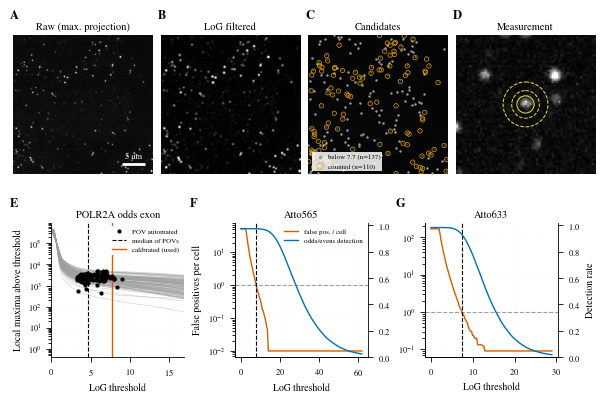

In [9]:
if os.environ.get("SMFISH_IMAGES") == "1":
    from smfish.figures import elbow_curves, fig_detection_steps, load_detection_example, pick_example_window
    from smfish.analysis import per_cell_counts

    PROBE, CHANNEL, WELLS = "POLR2A odds exon", "Atto565", [2, 3, 8, 9]
    raw_fovs = {p.name.split(".ome.tif")[0] for p in (plate.out.parents[1] / "data" / PLATE / "OME-TIFF").glob("*.ome.tif*")}
    counts = per_cell_counts(long, cells, PROBE, CHANNEL)
    window = pick_example_window(cells[cells["fov_id"].isin(raw_fovs)], counts[counts["fov_id"].isin(raw_fovs)],
                                 wells=WELLS, window_um=30)
    example = load_detection_example(plate.cfg, plate.agg / "spots.parquet", window, PROBE, CHANNEL)
    # fig_detection_steps panels F, G: the median-of-fields mrcB curve (section 3) and detection (section 4)
    mrcb = curve[(curve["probe"] == "mrcB") & (curve["kernel"] == "exon")]
    steps_scan = pd.concat([scan[scan["channel"] == ch].assign(fp_per_cell=lambda d, ch=ch: np.interp(
        d["threshold"], *mrcb.loc[mrcb["channel"] == ch, ["threshold", "fp_per_cell_median"]].T.values))
        for ch in ("Atto565", "Atto633")])
    used = {**thr_of, "channel": CHANNEL,
            "probe_median": float(proposed.loc[proposed["probe"] == PROBE, "probe_median_auto"].iloc[0])}
    with S.use("publication"):
        fig = fig_detection_steps(example, elbow_curves(plate.cfg, PROBE), steps_scan, used, plate.cfg,
                                  probe_label=PROBE)
        save(fig, "detection_steps", plate.figures)
        plt.show()
else:
    print("Skipped: set SMFISH_IMAGES=1 (needs a raw image in data/<plate>/OME-TIFF/ and outputs/<plate>/fov/*/qc.json)")